In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("data\telecom_churn.csv")
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB


In [5]:
df.head()


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [6]:
x=df[['AccountWeeks',	'ContractRenewal',	'DataPlan',	'DataUsage',	'CustServCalls',	'DayMins',	'DayCalls',	'MonthlyCharge',
      'OverageFee',	'RoamMins']]
y=df['Churn']

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Churn,3333.0,0.144914,0.352067,0.0,0.00,0.00,0.00,1.00
AccountWeeks,3333.0,101.064806,39.822106,1.0,74.00,101.00,127.00,243.00
ContractRenewal,3333.0,0.903090,0.295879,0.0,1.00,1.00,1.00,1.00
DataPlan,3333.0,0.276628,0.447398,0.0,0.00,0.00,1.00,1.00
DataUsage,3333.0,0.816475,1.272668,0.0,0.00,0.00,1.78,5.40
CustServCalls,3333.0,1.562856,1.315491,0.0,1.00,1.00,2.00,9.00
DayMins,3333.0,179.775098,54.467389,0.0,143.70,179.40,216.40,350.80
DayCalls,3333.0,100.435644,20.069084,0.0,87.00,101.00,114.00,165.00
MonthlyCharge,3333.0,56.305161,16.426032,14.0,45.00,53.50,66.20,111.30
OverageFee,3333.0,10.051488,2.535712,0.0,8.33,10.07,11.77,18.19


C:\Users\anaskhan\AppData\Local\Temp\ipykernel_4020\830580567.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(x='Churn',kind="count", palette='Set2', data=df)


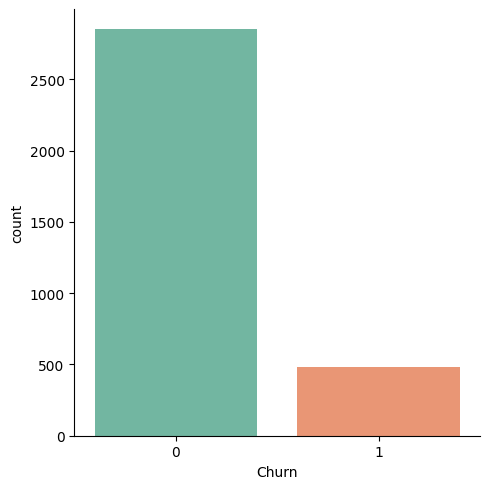

In [15]:
sns.catplot(x='Churn',kind="count", palette='Set2', data=df)

array([[<Axes: title={'center': 'Churn'}>,
        <Axes: title={'center': 'AccountWeeks'}>,
        <Axes: title={'center': 'ContractRenewal'}>],
       [<Axes: title={'center': 'DataPlan'}>,
        <Axes: title={'center': 'DataUsage'}>,
        <Axes: title={'center': 'CustServCalls'}>],
       [<Axes: title={'center': 'DayMins'}>,
        <Axes: title={'center': 'DayCalls'}>,
        <Axes: title={'center': 'MonthlyCharge'}>],
       [<Axes: title={'center': 'OverageFee'}>,
        <Axes: title={'center': 'RoamMins'}>, <Axes: >]], dtype=object)

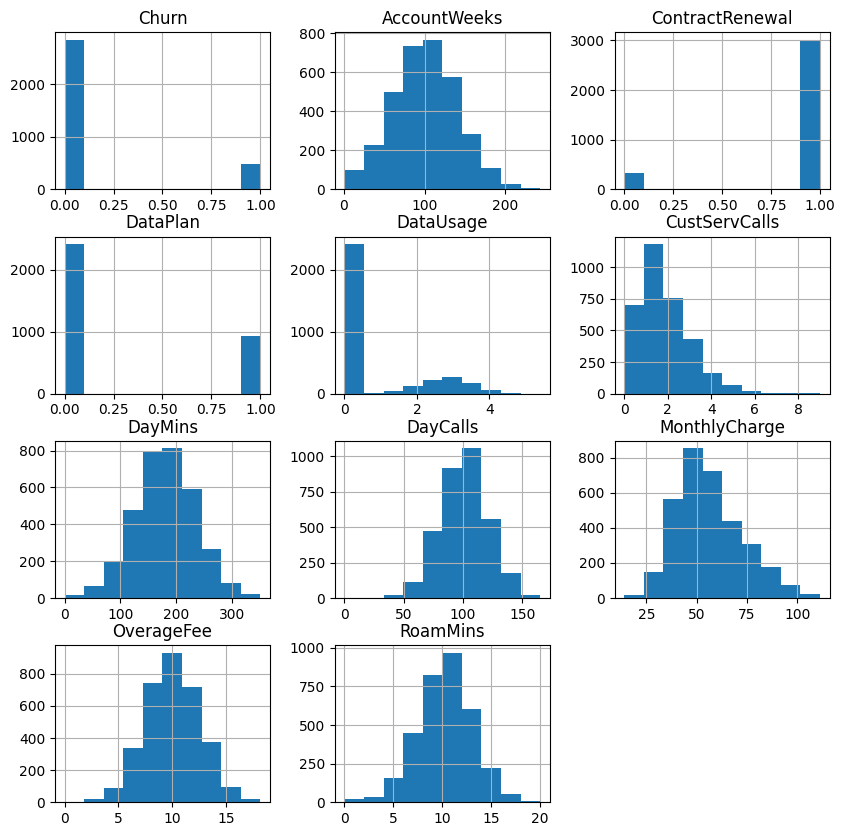

In [16]:
df.hist(figsize=(10,10))


<Axes: >

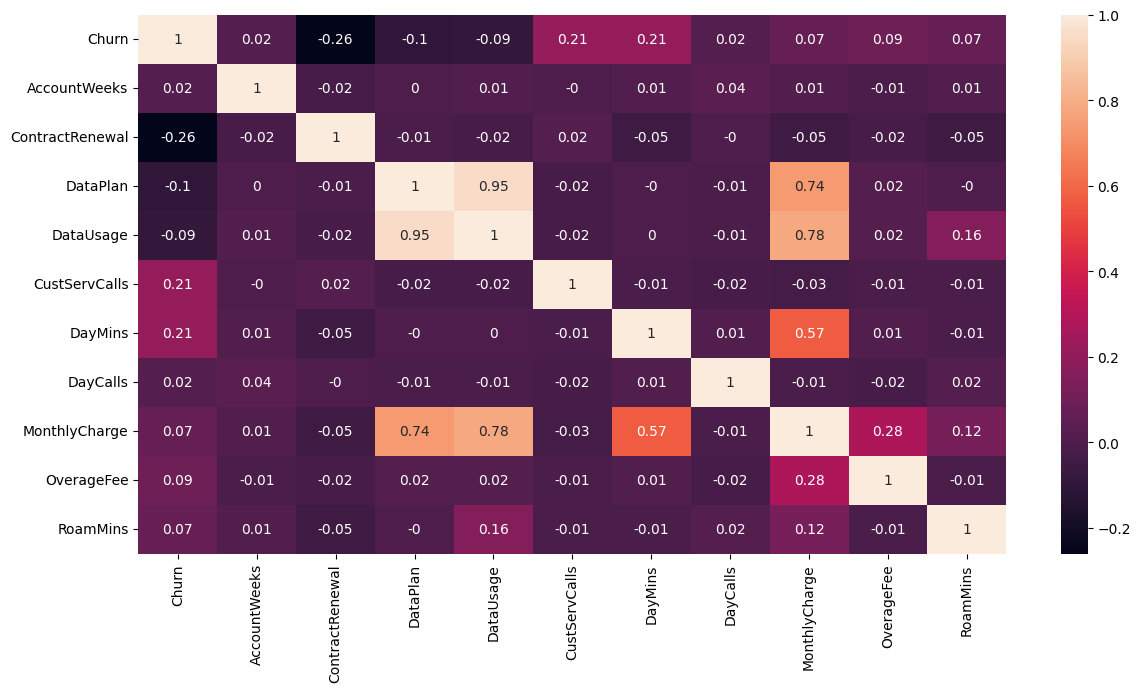

In [17]:
correlation = df.corr().round(2)
plt.figure(figsize = (14,7))
sns.heatmap(correlation, annot = True)

In [18]:
df.isnull().sum()/df.shape[0] * 100

Churn              0.0
AccountWeeks       0.0
ContractRenewal    0.0
DataPlan           0.0
DataUsage          0.0
CustServCalls      0.0
DayMins            0.0
DayCalls           0.0
MonthlyCharge      0.0
OverageFee         0.0
RoamMins           0.0
dtype: float64

In [33]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC


In [21]:
models={
    'svc': SVC(),
    "GaussianNB" : GaussianNB(), 
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Decision Tree" : DecisionTreeClassifier()}

In [24]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=32)

In [25]:
def fit_score(models,x_train,x_test,y_train,y_test):
    model_score={}
    for name,model in models.items():
        model.fit(x_train,y_train)
        model_score[name]=model.score(x_test,y_test)
    return model_score

model_scores= fit_score(models,x_train,x_test,y_train,y_test)
print(model_scores)


{'svc': 0.8575712143928036, 'GaussianNB': 0.8440779610194903, 'Logistic Regression': 0.8620689655172413, 'KNN': 0.8650674662668666, 'Random Forest': 0.9400299850074962, 'Decision Tree': 0.8845577211394303}


<Axes: >

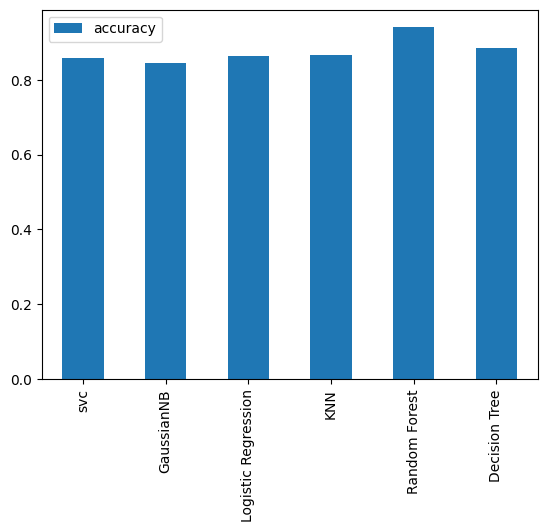

In [29]:
model_compare = pd.DataFrame(model_scores, index=["accuracy"])
model_compare.T.plot.bar()

In [36]:
from sklearn.model_selection import GridSearchCV

estimator=RandomForestClassifier()
params={
    'n_estimators':[50,100,200,250],
    'max_depth':[None,5,10,15],
    'min_samples_split':[2,5,10] ,
    'min_samples_leaf':[1,2,4] }
grid_search=GridSearchCV(estimator=estimator,param_grid=params,cv=5,scoring='recall',n_jobs=-1)
grid_search.fit(x_train,y_train)

print('Best Parameters : ', grid_search.best_params_,'\n')
print('Best Cross-Validation recall score: ',grid_search.best_score_,'\n')

best_estimator=grid_search.best_estimator_
test_accuracy=best_estimator.score(x_test,y_test)
print("Test Accuracy:", test_accuracy,'\n')

Best Parameters :  {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200} 

Best Cross-Validation accuracy score:  0.6685647685647685 

Test Accuracy: 0.9400299850074962 



In [38]:
from sklearn.metrics import classification_report,confusion_matrix

y_pred1=best_estimator.predict(x_test)

print("Classification Report\n",classification_report(y_test,y_pred1))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred1))

Classification Report
               precision    recall  f1-score   support

           0       0.95      0.98      0.97       570
           1       0.86      0.70      0.77        97

    accuracy                           0.94       667
   macro avg       0.91      0.84      0.87       667
weighted avg       0.94      0.94      0.94       667

Confusion Matrix:
 [[559  11]
 [ 29  68]]


In [42]:
# from imblearn.over_sampling import SMOTE
# smote=SMOTE()

# smote = SMOTE(random_state=42)
# X_train_res, y_train_res = smote.fit_resample(x_train, y_train)

# print("Before SMOTE:", y_train.value_counts())
# print("After SMOTE:", y_train_res.value_counts())

# # Train Random Forest on balanced data
# rf = RandomForestClassifier(max_depth=15, min_samples_leaf=1, min_samples_split=2, n_estimators=200,random_state=42)
# rf.fit(X_train_res, y_train_res)

# # Evaluate
# y_pred = rf.predict(x_test)
# print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
# print("\nClassification Report:\n", classification_report(y_test, y_pred))



Before SMOTE: Churn
0    2280
1     386
Name: count, dtype: int64
After SMOTE: Churn
0    2280
1    2280
Name: count, dtype: int64
Confusion Matrix:
 [[525  45]
 [ 19  78]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.92      0.94       570
           1       0.63      0.80      0.71        97

    accuracy                           0.90       667
   macro avg       0.80      0.86      0.83       667
weighted avg       0.92      0.90      0.91       667



array([0.05752754, 0.18438912, 0.05792417, 0.06974002, 0.11963001,
       0.17224766, 0.05412373, 0.16299032, 0.06669335, 0.05473408])

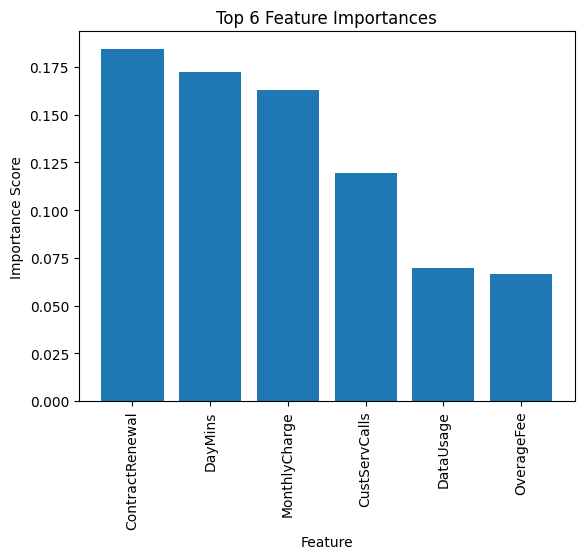

In [49]:
features=x.columns
importance=rf.feature_importances_
indices=np.argsort(importance)[::-1]
plt.bar(features[indices[:6]],importance[indices[:6]])
plt.title("Top 6 Feature Importances")
plt.ylabel("Importance Score")
plt.xlabel("Feature")
plt.xticks(rotation=90)
plt.show()

In [ ]:
!streamlit run churn_app.py